## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Shravya Etta

**Date:** 10/20/2026

**Q1**

In [3]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

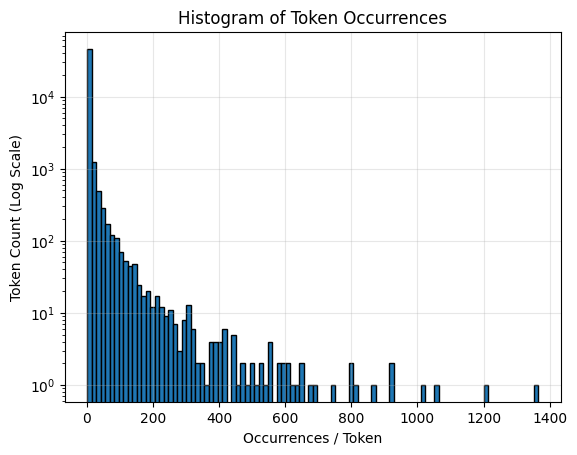

In [14]:
from collections import Counter
import matplotlib.pyplot as plt

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

plt.figure()
plt.hist(frequencies, bins=100, log=True, edgecolor='black')
plt.title("Histogram of Token Occurrences")
plt.xlabel("Occurrences / Token")
plt.ylabel("Token Count (Log Scale)")
plt.grid(True, alpha=0.3)
plt.show()

The majority of the tokens occur between 1 and 200 occurances while only a few occur in the thousands of occurances, causes leftward clustering. Hence, the shape of the distribution is a heavy-tailed to the left and follows Zipf's Law, where frequency is inversely proportion to its position when sorted from largest to smallest.

**Q2**

In [8]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_parquet('Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 80/20 train-test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# regression
lr = LinearRegression()
lr.fit(X_train, y_train)

# R^2
train_r2 = r2_score(y_train, lr.predict(X_train))
test_r2 = r2_score(y_test, lr.predict(X_test))

print(f"Train R^2: {train_r2:.3f}")
print(f"Test R^2:  {test_r2:.3f}")

# major words
coef_df = pd.DataFrame({'Token': X.columns, 'Coefficient': lr.coef_})
coef_df['Abs_Coef'] = coef_df['Coefficient'].abs()
top_words = coef_df.sort_values(by='Abs_Coef', ascending=False).head(15)
print(top_words[['Token', 'Coefficient']])

Train R^2: 0.767
Test R^2:  0.666
                  Token  Coefficient
835        intervention    -1.259257
740           localized     0.824350
2362            thermal     0.747006
851             crawler     0.696167
1504  background-image:    -0.622909
1406         helvetica,     0.598560
906               aging     0.594956
1839              form.     0.576886
2242              gray;    -0.574480
1552           a:active     0.574480
1494         retrieving    -0.573761
2657              zdnet    -0.560954
1245  {text-decoration:     0.497075
2532             xanaax     0.491981
2566         transcript     0.488978


The gap between train and test shows some overfitting, which is expected considering that there are 2,711 features.

The strongest predictors are associated with the largest coefficients, most of which are noisy in the sense that many of the tokens look like HTML/CSS fragments (ex. "helvetica", "background-image", and "a:active". These could be from legitimate or scam emails. Additionally, other tokens like "zdnet" and "retrieving" are more indicative of real, not scam, emails.

**Q3**

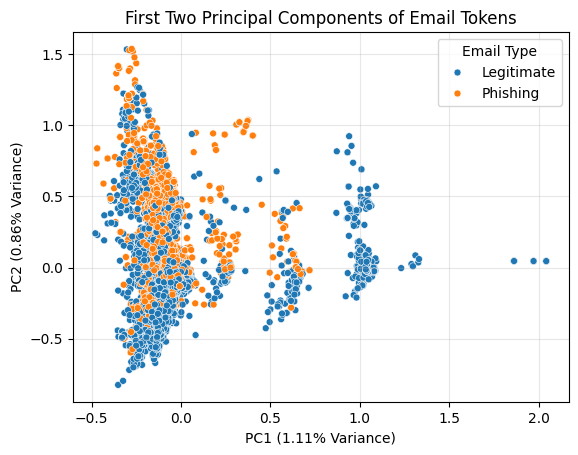

In [15]:
import seaborn as sns
from sklearn.decomposition import PCA

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame({
    'PC1': X_pca_2[:, 0],
    'PC2': X_pca_2[:, 1],
    'Email Type': y.map({1: 'Phishing', 0: 'Legitimate'})
})

plt.figure()
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', s=25)
plt.title("First Two Principal Components of Email Tokens")
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.grid(True, alpha=0.3)
plt.show()

The scatter plot is dispersed greater vertically at specific spokes along the x-axis that are centered near the origin. This is likely since the input matrix is binary and there are zero-value entries.

The legitimate emails are either clustered closer to the origin or spread out at points along the x-axis that are associated with normal vocabulary in correspondance. The phishing emails, on the other hand, are likely spread out along x-axis values that are domainant token combinations with spam marking or credential-seeking vocabulary.

**Q4**

In [18]:
pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pcr = LinearRegression()
pcr.fit(X_train_pca, y_train)

pcr_train_r2 = r2_score(y_train, pcr.predict(X_train_pca))
pcr_test_r2 = r2_score(y_test, pcr.predict(X_test_pca))

print(f"PCR Train R^2: {pcr_train_r2:.3f}")
print(f"PCR Test R^2:  {pcr_test_r2:.3f}")

PCR Train R^2: 0.766
PCR Test R^2:  0.668


The training and testing R^2 values are still close to the standard regression because the 2610 features used still contains almost all of the of the variance in the original 2711 features. The small changes are a result of removing the last ~100 that are already noisy and have near-zero variance.

**Q5**

One advantage of using the principal components instead of the original data is that it eliminates multicollinearity. The original word occurrences have high multicollineary because of associated/correlated words, and this causes coefficients to be inflated at the regression to be numerically unstable.

Additionally, it allows for reducing dimensionality by only keeping the top features and dropping those that carry a lot of noise. This results in less overfitting, which is a common occurence with there are thousands of features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]